In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import random
import matplotlib.pyplot as plt
import json


In [3]:
df = pd.read_csv("dataset/career_path_dataset_encoded.csv")
df.head()


,I am the life of the party.,I get stressed out easily.,I pay attention to details.,I sympathize with others’ feelings.,I have a rich vocabulary.,What is your CGPA range?,Which stream are you studying?,Do you prefer practical assignments over theory?,Rate your logical reasoning ability.,How do you rate your problem-solving skills.,...,Rate your creativity level.,Primary interest,Experience level,Projects completed,Certifications,Preferred career type,Preferred industry,Preferred work environment,Career goal,recommended_career
0,0,0,2,0,2,1,1,1,2,3,...,2,0,2,1,0,0,5,1,1,7
1,1,0,0,0,0,1,4,1,0,1,...,2,6,1,0,3,4,1,3,3,10
2,1,0,0,1,2,0,1,0,1,0,...,2,2,2,2,3,4,5,3,3,4
3,2,1,1,0,2,0,1,2,2,2,...,1,5,2,1,1,1,1,3,0,5
4,0,0,0,2,2,1,1,2,3,0,...,0,0,0,2,3,2,1,0,0,7


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7867 entries, 0 to 7866
Data columns (total 22 columns):
 #   Column                                            Non-Null Count  Dtype
---  ------                                            --------------  -----
 0   I am the life of the party.                       7867 non-null   int64
 1   I get stressed out easily.                        7867 non-null   int64
 2   I pay attention to details.                       7867 non-null   int64
 3   I sympathize with others’ feelings.               7867 non-null   int64
 4   I have a rich vocabulary.                         7867 non-null   int64
 5   What is your CGPA range?                          7867 non-null   int64
 6   Which stream are you studying?                    7867 non-null   int64
 7   Do you prefer practical assignments over theory?  7867 non-null   int64
 8   Rate your logical reasoning ability.              7867 non-null   int64
 9   How do you rate your problem-solving skil

In [5]:
df.columns

Index(['I am the life of the party.', 'I get stressed out easily.',
       'I pay attention to details.', 'I sympathize with others’ feelings.',
       'I have a rich vocabulary.', 'What is your CGPA range?',
       'Which stream are you studying?',
       'Do you prefer practical assignments over theory?',
       'Rate your logical reasoning ability.',
       'How do you rate your problem-solving skills.',
       'Rate your programming knowledge.',
       'How are your communication skills?', 'Rate your creativity level.',
       'Primary interest', 'Experience level', 'Projects completed',
       'Certifications', 'Preferred career type', 'Preferred industry',
       'Preferred work environment', 'Career goal', 'recommended_career'],
      dtype='object')

In [6]:
df.isnull().sum()

I am the life of the party.                         0
I get stressed out easily.                          0
I pay attention to details.                         0
I sympathize with others’ feelings.                 0
I have a rich vocabulary.                           0
What is your CGPA range?                            0
Which stream are you studying?                      0
Do you prefer practical assignments over theory?    0
Rate your logical reasoning ability.                0
How do you rate your problem-solving skills.        0
Rate your programming knowledge.                    0
How are your communication skills?                  0
Rate your creativity level.                         0
Primary interest                                    0
Experience level                                    0
Projects completed                                  0
Certifications                                      0
Preferred career type                               0
Preferred industry          

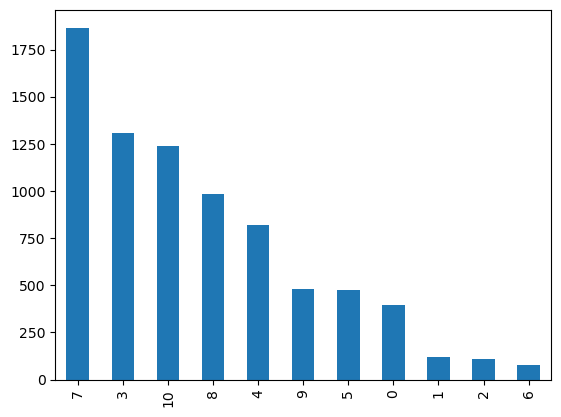

In [7]:
df.recommended_career.value_counts().plot(kind='bar');

In [8]:
df.to_csv("dataset/processed.csv", index=False)


In [9]:
df.head()


,I am the life of the party.,I get stressed out easily.,I pay attention to details.,I sympathize with others’ feelings.,I have a rich vocabulary.,What is your CGPA range?,Which stream are you studying?,Do you prefer practical assignments over theory?,Rate your logical reasoning ability.,How do you rate your problem-solving skills.,...,Rate your creativity level.,Primary interest,Experience level,Projects completed,Certifications,Preferred career type,Preferred industry,Preferred work environment,Career goal,recommended_career
0,0,0,2,0,2,1,1,1,2,3,...,2,0,2,1,0,0,5,1,1,7
1,1,0,0,0,0,1,4,1,0,1,...,2,6,1,0,3,4,1,3,3,10
2,1,0,0,1,2,0,1,0,1,0,...,2,2,2,2,3,4,5,3,3,4
3,2,1,1,0,2,0,1,2,2,2,...,1,5,2,1,1,1,1,3,0,5
4,0,0,0,2,2,1,1,2,3,0,...,0,0,0,2,3,2,1,0,0,7


In [10]:
X = df.drop('recommended_career', axis=1)
y = df['recommended_career']

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((6293, 21), (6293,), (1574, 21), (1574,))

In [12]:
ML_Model = []
accuracy = []
precision = []
recall = []
f1score = []

#function to call for storing the results
def storeResults(model, a,b,c,d):
    ML_Model.append(model)
    accuracy.append(round(a, 3))
    precision.append(round(b, 3))
    recall.append(round(c, 3))
    f1score.append(round(d, 3))

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# RF

In [14]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier()
# fit the model 
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

rf_acc = accuracy_score(y_pred, y_test)
rf_prec = precision_score(y_pred, y_test,average='weighted')
rf_rec = recall_score(y_pred, y_test,average='weighted')
rf_f1 = f1_score(y_pred, y_test,average='weighted')

In [15]:
storeResults('RandomForest',rf_acc,rf_prec,rf_rec,rf_f1)

In [16]:

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix for RF:")
print(cm)


cr = classification_report(y_test, y_pred)
print("\nClassification Report for RF:")
print(cr)

Confusion Matrix for RF:
[[ 22   0   0  25   3   0   0  10  13   0   1]
 [  0   3   0   3   2   0   0  12   1   0   1]
 [  0   0   2   3   1   0   0   9   0   0   7]
 [  1   0   0 252   0   0   0   3   0   0   0]
 [  0   0   0  23 105   0   0   6  11   1   6]
 [  0   0   0  16   6  24   0  21  11   0  16]
 [  0   0   0   1   5   1   0   6   2   0   2]
 [  1   0   0   3   1   0   0 350   8   0  14]
 [  0   1   0   8   4   0   0  19 172   2   4]
 [  0   0   0   3   0   0   0   1   0  95   0]
 [  3   0   0   3   3   0   0  16   2   2 222]]

Classification Report for RF:
              precision    recall  f1-score   support

           0       0.81      0.30      0.44        74
           1       0.75      0.14      0.23        22
           2       1.00      0.09      0.17        22
           3       0.74      0.98      0.85       256
           4       0.81      0.69      0.74       152
           5       0.96      0.26      0.40        94
           6       0.00      0.00      0.00    

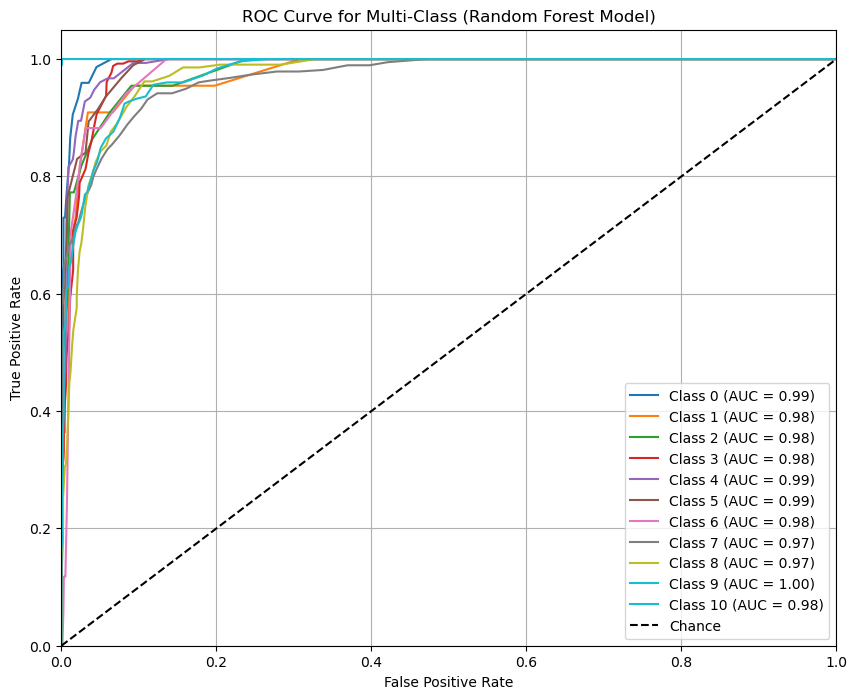

In [18]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc



classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]


y_score = clf.predict_proba(X_test)


fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(10, 8))
colors = plt.cm.get_cmap('tab10', n_classes)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors(i),
             label=f"Class {classes[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multi-Class (Random Forest Model)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# SVM

In [19]:
from sklearn.svm import SVC

clf = SVC(gamma='auto',probability=True)
# fit the model 
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

svm_acc = accuracy_score(y_pred, y_test)
svm_prec = precision_score(y_pred, y_test,average='weighted')
svm_rec = recall_score(y_pred, y_test,average='weighted')
svm_f1 = f1_score(y_pred, y_test,average='weighted')

In [20]:
storeResults('SVM',svm_acc,svm_prec,svm_rec,svm_f1)

In [21]:

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix for SVM:")
print(cm)


cr = classification_report(y_test, y_pred)
print("\nClassification Report for SVM:")
print(cr)

Confusion Matrix for SVM:
[[ 26   0   0  22   0   2   0  13   7   0   4]
 [  0   0   1   4   2   5   0   6   3   0   1]
 [  0   0   0   3   1   1   0  13   0   0   4]
 [ 12   0   0 146   7   6   0  38  17  15  15]
 [  0   0   0  37  49   3   0  23  14   2  24]
 [  3   0   0  19   1  32   0  12  10   0  17]
 [  1   0   0   2   4   1   0   6   3   0   0]
 [  2   0   0  21  11   5   0 286  20   4  28]
 [  7   0   0  50  15   6   0  57  53   4  18]
 [  0   0   0   7   0   0   0   3   0  88   1]
 [  7   0   0  29  16   6   0  39  14  14 126]]

Classification Report for SVM:
              precision    recall  f1-score   support

           0       0.45      0.35      0.39        74
           1       0.00      0.00      0.00        22
           2       0.00      0.00      0.00        22
           3       0.43      0.57      0.49       256
           4       0.46      0.32      0.38       152
           5       0.48      0.34      0.40        94
           6       0.00      0.00      0.00  

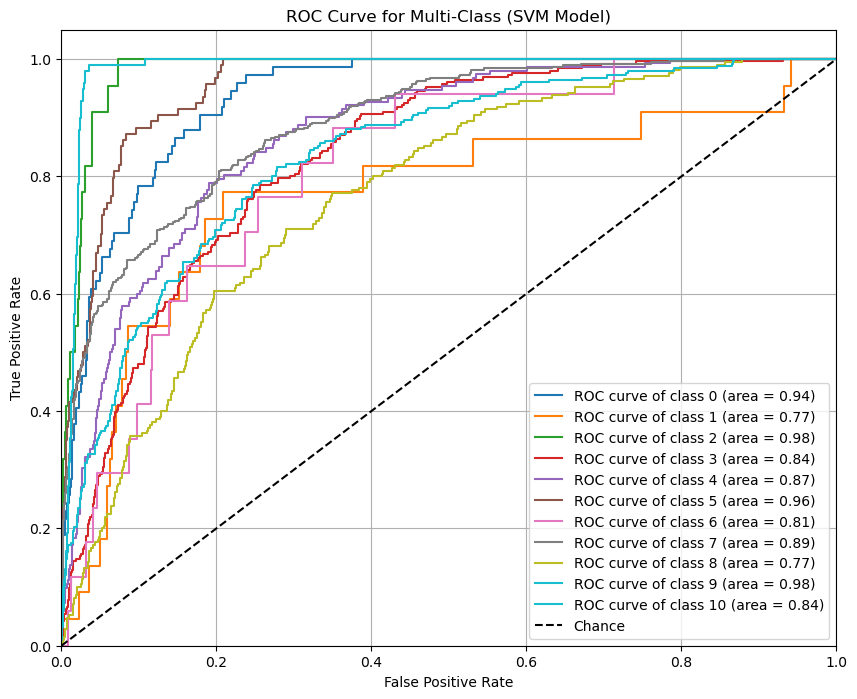

In [22]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc



classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]


y_score = clf.predict_proba(X_test)


fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])


plt.figure(figsize=(10, 8))
colors = plt.cm.get_cmap('tab10', n_classes)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors(i),
             label=f"ROC curve of class {classes[i]} (area = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multi-Class (SVM Model)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# XGB

In [23]:
from xgboost import XGBClassifier

xgb = XGBClassifier(learning_rate=0.1,
    n_estimators=200,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.5,                # L1 regularization
    reg_lambda=1.0,               # L2 regularization
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss')
 
xgb.fit(X_train, y_train)

y_pred = xgb.predict(X_test)

xg_acc = accuracy_score(y_pred, y_test)
xg_prec = precision_score(y_pred, y_test,average='weighted')
xg_rec = recall_score(y_pred, y_test,average='weighted')
xg_f1 = f1_score(y_pred, y_test,average='weighted')

In [24]:
storeResults('XGBoost',xg_acc,xg_prec,xg_rec,xg_f1)

In [25]:

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix for XGB:")
print(cm)


cr = classification_report(y_test, y_pred)
print("\nClassification Report for XGB:")
print(cr)

Confusion Matrix for XGB:
[[ 74   0   0   0   0   0   0   0   0   0   0]
 [  0  22   0   0   0   0   0   0   0   0   0]
 [  0   0  22   0   0   0   0   0   0   0   0]
 [  0   0   0 256   0   0   0   0   0   0   0]
 [  0   0   0   0 152   0   0   0   0   0   0]
 [  0   0   0   0   0  94   0   0   0   0   0]
 [  0   0   0   1   0   0  16   0   0   0   0]
 [  0   0   1   0   0   0   0 376   0   0   0]
 [  0   0   0   0   0   0   0   0 210   0   0]
 [  0   0   0   0   0   0   0   0   0  99   0]
 [  0   0   0   0   0   0   0   1   0   0 250]]

Classification Report for XGB:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        74
           1       1.00      1.00      1.00        22
           2       0.96      1.00      0.98        22
           3       1.00      1.00      1.00       256
           4       1.00      1.00      1.00       152
           5       1.00      1.00      1.00        94
           6       1.00      0.94      0.97  

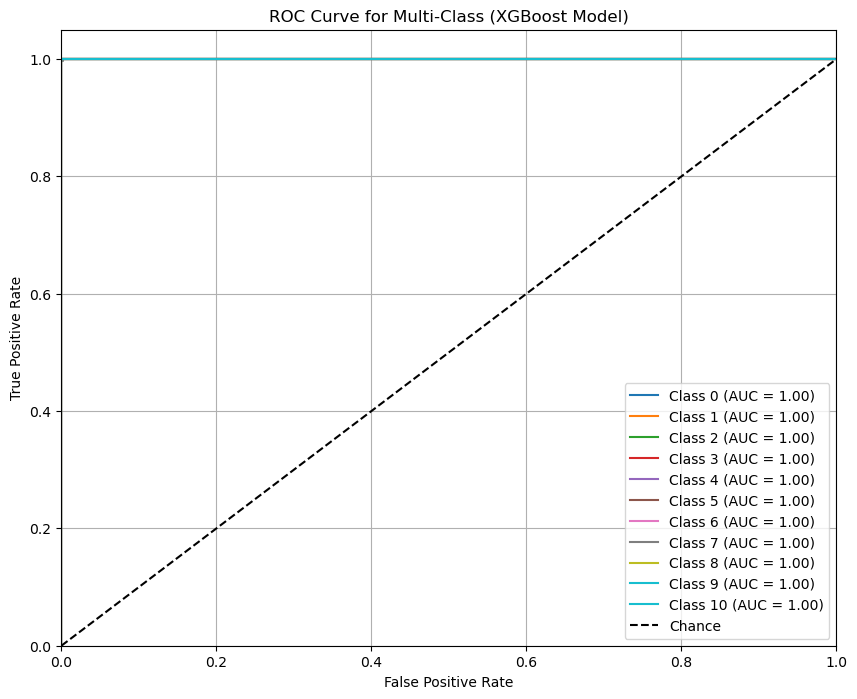

In [26]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np


classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

y_score = xgb.predict_proba(X_test)


fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])


plt.figure(figsize=(10, 8))
colors = plt.cm.get_cmap('tab10', n_classes)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors(i),
             label=f"Class {classes[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multi-Class (XGBoost Model)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# Ensemble

In [27]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


In [28]:
xgb = XGBClassifier(
    learning_rate=0.1,
    n_estimators=200,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.5,
    reg_lambda=1.0,
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

cat = CatBoostClassifier(
    iterations=200,
    learning_rate=0.1,
    depth=6,
    random_seed=42,
    verbose=0
)

lgb = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=1.0,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42
)


In [29]:
voting_clf = VotingClassifier(
    estimators=[
        ('xgb', xgb),
        ('cat', cat),
        ('lgb', lgb),
        ('rf', rf)
    ],
    voting='soft',  
    n_jobs=-1
)


In [30]:
# Train
voting_clf.fit(X_train, y_train)

# Predict
y_pred = voting_clf.predict(X_test)

# Evaluate
voting_acc = accuracy_score(y_test, y_pred)
voting_prec = precision_score(y_test, y_pred, average='weighted')
voting_rec = recall_score(y_test, y_pred, average='weighted')
voting_f1 = f1_score(y_test, y_pred, average='weighted')



cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix for Voting Classifier:")
print(cm)


cr = classification_report(y_test, y_pred)
print("\nClassification Report for Voting Classifier:")
print(cr)


Confusion Matrix for Voting Classifier:
[[ 74   0   0   0   0   0   0   0   0   0   0]
 [  0  22   0   0   0   0   0   0   0   0   0]
 [  0   0  22   0   0   0   0   0   0   0   0]
 [  0   0   0 256   0   0   0   0   0   0   0]
 [  0   0   0   0 152   0   0   0   0   0   0]
 [  0   0   0   0   0  94   0   0   0   0   0]
 [  0   0   0   1   0   0  16   0   0   0   0]
 [  0   0   0   0   0   0   0 377   0   0   0]
 [  0   0   0   0   0   0   0   0 210   0   0]
 [  0   0   0   0   0   0   0   0   0  99   0]
 [  0   0   0   0   0   0   0   0   0   0 251]]

Classification Report for Voting Classifier:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        74
           1       1.00      1.00      1.00        22
           2       1.00      1.00      1.00        22
           3       1.00      1.00      1.00       256
           4       1.00      1.00      1.00       152
           5       1.00      1.00      1.00        94
           6     

  File "C:\ProgramData\anaconda3\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\ProgramData\anaconda3\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\ProgramData\anaconda3\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\ProgramData\anaconda3\lib\subprocess.py", line 1440, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


In [31]:
storeResults('VotingClassifier', voting_acc, voting_prec, voting_rec, voting_f1)


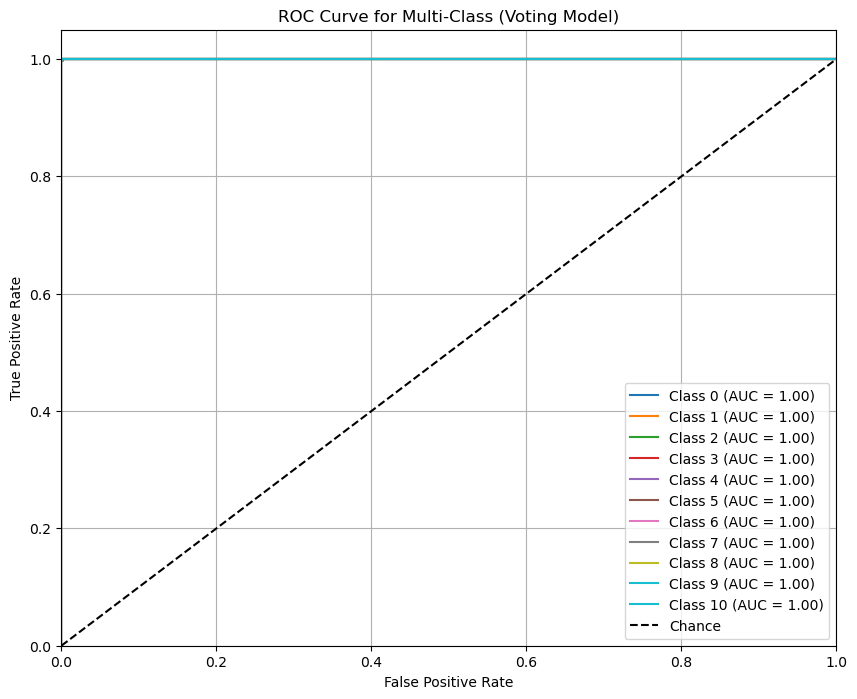

In [32]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np


classes = np.unique(y_train)
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

y_score = voting_clf.predict_proba(X_test)


fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])


plt.figure(figsize=(10, 8))
colors = plt.cm.get_cmap('tab10', n_classes)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors(i),
             label=f"Class {classes[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multi-Class (Voting Model)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# Comparision

In [33]:
#creating dataframe
import pandas as pd
import numpy as np
result = pd.DataFrame({ 'ML Model' : ML_Model,
                        'Accuracy' : accuracy,
                        'f1_score' : f1score,
                        'Recall'   : recall,
                        'Precision': precision,
                                                
                      })

In [34]:
result

,ML Model,Accuracy,f1_score,Recall,Precision
0,RandomForest,0.792,0.821,0.792,0.875
1,SVM,0.512,0.537,0.512,0.582
2,XGBoost,0.998,0.998,0.998,0.998
3,VotingClassifier,0.999,0.999,0.999,0.999


# Graph

In [35]:
classifier = ML_Model
y_pos = np.arange(len(classifier))

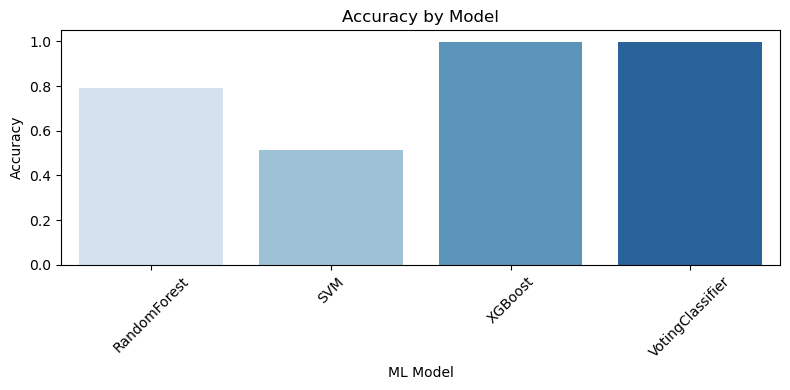

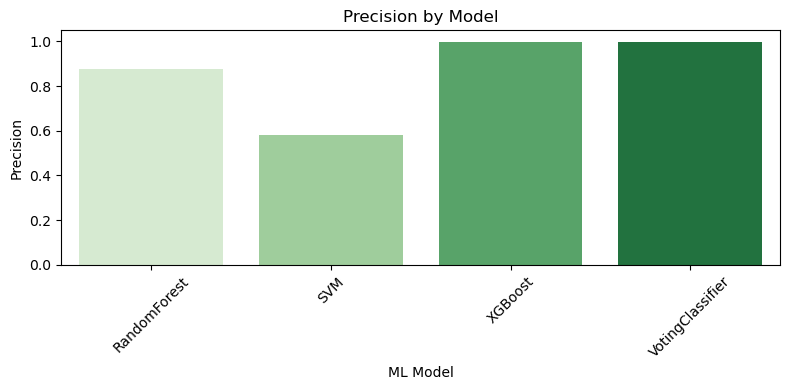

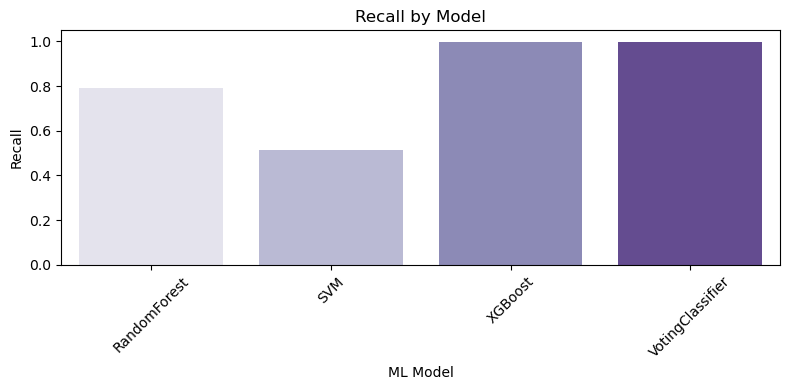

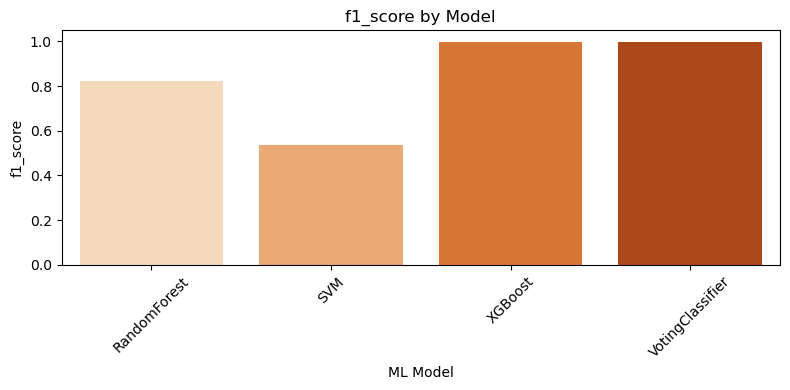

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define a different palette for each metric
palettes = {
    'Accuracy': 'Blues',
    'Precision': 'Greens',
    'Recall': 'Purples',
    'f1_score': 'Oranges',
    
}

for metric in ['Accuracy', 'Precision', 'Recall', 'f1_score']:
    plt.figure(figsize=(8, 4))
    sns.barplot(data=result, x='ML Model', y=metric, palette=palettes[metric])
    plt.title(f'{metric} by Model')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Modeling

In [38]:
import joblib


joblib.dump(xgb, 'Models/xgb_model.sav')

joblib.dump(voting_clf, 'Models/vot_model.sav')

['Models/vot_model.sav']

In [59]:
vot = joblib.load('Models/vot_model.sav')

In [60]:
from lime import lime_tabular
import plotly.graph_objects as go

feature_names = X.columns.tolist()

X_train_np = X_train if isinstance(X_train, np.ndarray) else X_train.to_numpy()
X_test_np = X_test if isinstance(X_test, np.ndarray) else X_test.to_numpy()

# --- LIME Explainer ---
lime_explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=feature_names,
    
    mode='classification'
)

# --- Explain a Single Instance ---
i = 5  # index of test sample to explain
explanation = lime_explainer.explain_instance(
    data_row=X_test_np[i],
    predict_fn=vot.predict_proba,
    top_labels=1,
    num_features=21
)

# --- Display Explanation in Notebook ---
explanation.show_in_notebook()

In [62]:

# --- Explain a Single Instance ---
i = 2  # index of test sample to explain
explanation = lime_explainer.explain_instance(
    data_row=X_test_np[i],
    predict_fn=vot.predict_proba,
    top_labels=1,
    num_features=21
)

# --- Display Explanation in Notebook ---
explanation.show_in_notebook()

In [63]:

# --- Explain a Single Instance ---
i = 28  # index of test sample to explain
explanation = lime_explainer.explain_instance(
    data_row=X_test_np[i],
    predict_fn=vot.predict_proba,
    top_labels=1,
    num_features=21
)

# --- Display Explanation in Notebook ---
explanation.show_in_notebook()

# Prediction

In [64]:
import joblib
import numpy as np
import pandas as pd

model = joblib.load('Models/vot_model.sav')

In [65]:
data = [0,0,2,2,1,0,3,2,3,2,2,2,2,2,1,3,2,1,2,1,1]

In [66]:
data = np.array(data).reshape(1, -1)

prediction = model.predict(data)

print("Predicted class:", prediction[0])

Predicted class: 4


In [67]:
data = [0,0,2,0,2,1,1,1,2,3,2,0,2,0,2,1,0,0,5,1,1]

In [68]:
data = np.array(data).reshape(1, -1)

prediction = model.predict(data)

print("Predicted class:", prediction[0])

Predicted class: 7
